# Scratch100k taxv2: the taxonomy losses rerun on the fixed concept table

The four scratch100k runs from `Scratch100k_Loss_Comparison.ipynb` (base, distance / KL / partial CE at w=0.1), retrained
from scratch on the **fixed concept table** (`configs/class_to_concepts.csv`, 706 → 703 concept channels). Same recipe as
before: 75k updates at constant LR then a 25k cooldown, 256 px, dedup CoralNet splits, data seed 4
(`sbatch slurm/scratch100k_train.sbatch <LOSS> [0.1] tag=taxv2`).

What changed in the table (sections 1 and 4 show what it does to the metrics):
- **Turbinaria split in two**: `genus__turbinaria` (a coral genus in Dendrophylliidae *and* a brown-alga genus in
  Sargassaceae) → `genus__turbinaria_coral` and `genus__turbinaria_algae`. Every taxon now has one parent, so the tree
  builds under `ambiguity_policy="strict"`, and KL no longer splits turbinaria's mass across two families.
- **Seagrass gets a phylum and class**: `phylum__tracheophyta`, `class__liliopsida` (replacing `order__asterales` /
  `family__asteraceae`).
- **Anemone / sponge fixes**: `genus__radianthus` replaces `family__radianthus`, `genus__magnifica`, `genus__malu`,
  `order__stichodactylidae`; `class__keratosa` removed.

Each run pins its own copy of the CSV in `nbs/model_checkpoints/<RUN>/class_to_concepts.csv`, and is evaluated against that
copy and its own 703-channel concept map (`slurm/scratch100k_launch_evals.sh`). The old runs were evaluated against the old
CSV.

**Comparing old with new.** Class accuracy (79 MERMAID classes), Benthos and CoralscapesV2 do not depend on the concept
table, so old and new runs compare directly. Rank accuracy, consistency, severity and the loss objectives are computed on
each run's own tree, so an old-vs-new difference there mixes the model change with the change in what is being scored.
Within the taxv2 runs (sections 5–7), everything is on the same tree.

Figures for the same data: `eval_out/scratch100k_hier/plots_taxv2/` and `plots_taxv1_vs_v2/`
(`scripts/plot_hierarchical_evals.py --runs ... --out-dir ...`).

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.lines import Line2D

REPO = Path("..").resolve() if Path("../eval_out").exists() else Path(".").resolve()
ROOT = REPO / "eval_out/scratch100k_hier"
CKPTS = REPO / "nbs/model_checkpoints"
PREFIX = "cbm_scratch100k_"
TAG = "taxv2"
RES = 256
RANKS = ["kingdom", "phylum", "class", "order", "family", "genus"]
PAIRS = [f"{c}->{f}" for c, f in zip(RANKS, RANKS[1:])]
EVALS = {"coralnet": "CoralNet val (dedup)", "pacific": "Pacific val"}
COOLDOWN = (75000, 100000)  # linear LR cooldown to 0
REF = f"base_{TAG}"

# Hue = loss, as in scripts/plot_hierarchical_evals.py. New (taxv2) runs: full colour, solid; their old-CSV
# counterparts: lighter, dotted, so old vs new is never colour-only.
LOSSES = {
    "base": ("base", "#2a78d6", "o"),
    "distance": ("distance", "#eb6834", "s"),
    "kl": ("KL", "#1baf7a", "^"),
    "partial": ("partial CE", "#eda100", "D"),
}
INK, MUTED, GRID, BAND, SURFACE = "#1c1c1a", "#6b6a64", "#e4e3df", "#ebeae6", "#fcfcfb"


def shade(color, mix):
    rgb = [int(color[i:i + 2], 16) for i in (1, 3, 5)]
    target = 255 if mix > 0 else 0
    return "#" + "".join(f"{round(c + (target - c) * abs(mix)):02x}" for c in rgb)


def parse(run):
    """'kl_w0.1_taxv2' -> ('kl', '0.1', 'taxv2')."""
    tag = ""
    if run.endswith("_" + TAG):
        run, tag = run.removesuffix("_" + TAG), TAG
    loss, _, weight = run.partition("_w")
    return loss, weight, tag


def style(run):
    """(label, colour, marker, linestyle) of a short run name."""
    loss, weight, tag = parse(run)
    name, color, marker = LOSSES[loss]
    label = f"{name} w={weight}" if weight else name
    if tag:
        return label, color, marker, "-"
    return f"{label} (old CSV)", shade(color, 0.5), marker, ":"


def order(run):
    loss, weight, tag = parse(run)
    return list(LOSSES).index(loss), not tag, float(weight or 0)


def old_of(run):
    return run.removesuffix("_" + TAG)


plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "axes.titlesize": 10, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.frameon": False, "figure.dpi": 100,
})
pd.set_option("display.width", 200)

df = pd.read_csv(ROOT / "compiled.csv")
df = df[df.resolution == RES].copy()
df["run"] = df.run.str.removeprefix(PREFIX)
# The w=0.1 runs only; the w=0.5 / KL + partial CE taxv2 runs are in Scratch100k_TaxV2_Weights.ipynb.
NEW = sorted(r for r in df.run.unique() if parse(r)[2] == TAG and parse(r)[1] in ("", "0.1"))
OLD = [old_of(r) for r in NEW if old_of(r) in set(df.run)]
df = df[df.run.isin(NEW + OLD)].sort_values(["run", "step"]).set_index(["run", "step"])
EVALUATED = {r: sorted(df.loc[r].index) for r in NEW + OLD}
NEW_STEPS = sorted({s for r in NEW for s in EVALUATED[r]})
COMPARE = [r for r in NEW if r != REF]


def plot_run(ax, run, x, y, **kw):
    label, color, marker, ls = style(run)
    ax.plot(x, y, color=color, marker=marker, ls=ls, lw=2, ms=6, mec="white", mew=0.8, label=label, **kw)


def step_axis(ax, steps):
    ax.set_xticks(steps)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v / 1000)}k"))
    if steps[-1] > COOLDOWN[0]:
        ax.axvspan(*COOLDOWN, color=BAND, lw=0, zorder=0)


def run_legend(fig, runs, y=1.0, ncol=None):
    handles = [Line2D([], [], color=style(r)[1], marker=style(r)[2], ls=style(r)[3], lw=2, label=style(r)[0]) for r in runs]
    fig.legend(handles=handles, loc="upper right", ncol=ncol or len(handles), bbox_to_anchor=(1, y), fontsize=9)


def delta(run, col, ref=REF):
    """run − ref at the steps both have (raw units), as a Series indexed by step."""
    a, b = df.loc[run, col], df.loc[ref, col]
    common = [s for s in a.index if s in b.index]
    return a.loc[common] - b.loc[common]


print("new runs:", NEW)
print("old counterparts:", OLD)
print("steps evaluated (new):", NEW_STEPS)

new runs: ['base_taxv2', 'distance_w0.1_taxv2', 'kl_w0.1_taxv2', 'partial_w0.1_taxv2']
old counterparts: ['base', 'distance_w0.1', 'kl_w0.1', 'partial_w0.1']
steps evaluated (new): [25000, 50000, 75000, 100000]


## 0. What has been evaluated
Checkpoints on disk and finished evals (rows of `compiled.csv`), and the checksum of each run's pinned concept CSV: all
four should match. The old runs predate pinning and read the live CSV, which was the old table at the time.

In [2]:
on_disk = {}
for d in sorted(CKPTS.glob(PREFIX + "*")):
    name = d.name.removeprefix(PREFIX)
    run = name.removesuffix("_cd")
    if run not in NEW:
        continue
    for ck in d.glob("model_epoch*"):
        epoch = int(ck.name.removeprefix("model_epoch"))
        step = 100000 + 25000 * epoch if name.endswith("_cd") else 25000 * (epoch + 1)
        on_disk.setdefault(run, set()).add(step)


def csv_sha(run):
    p = CKPTS / f"{PREFIX}{run}/class_to_concepts.csv"
    return hashlib.sha1(p.read_bytes()).hexdigest()[:12] if p.exists() else "—"


status = pd.DataFrame(
    [[("evaluated" if s in EVALUATED.get(r, []) else "ckpt, not evaluated" if s in on_disk.get(r, set()) else "—")
      for s in (25000, 50000, 75000, 100000)] + [csv_sha(r)] for r in NEW],
    index=[style(r)[0] for r in NEW], columns=["25k", "50k", "75k", "100k (cooldown)", "pinned CSV sha1"])
status

,25k,50k,75k,100k (cooldown),pinned CSV sha1
base,evaluated,evaluated,evaluated,evaluated,d46f6fe76c31
distance w=0.1,evaluated,evaluated,evaluated,evaluated,d46f6fe76c31
KL w=0.1,evaluated,evaluated,evaluated,evaluated,d46f6fe76c31
partial CE w=0.1,evaluated,evaluated,evaluated,evaluated,d46f6fe76c31


## 1. The concept channels, old vs new
From the two concept maps the evals used (`eval_out/scratch100k_hier/concept_id2name.json` for the old runs,
`<RUN>/concept_id2name.json` for the new ones).

In [3]:
old_map = json.loads((ROOT / "concept_id2name.json").read_text())
new_map = json.loads((ROOT / f"{PREFIX}{REF}" / "concept_id2name.json").read_text())
old_names, new_names = set(old_map.values()), set(new_map.values())
print(f"channels: {len(old_map)} -> {len(new_map)}")
print("added:  ", sorted(new_names - old_names))
print("removed:", sorted(old_names - new_names))

channels: 706 -> 703
added:   ['class__liliopsida', 'genus__radianthus', 'genus__turbinaria_algae', 'genus__turbinaria_coral', 'phylum__tracheophyta']
removed: ['class__keratosa', 'family__asteraceae', 'family__radianthus', 'genus__magnifica', 'genus__malu', 'genus__turbinaria', 'order__asterales', 'order__stichodactylidae']


## 2. Headline metrics: new runs vs their old-CSV counterparts
Solid = taxv2, dotted = the same loss on the old table. None of these four metrics depends on the concept tree, so the
lines compare directly. Grey = LR cooldown, once a run reaches it.

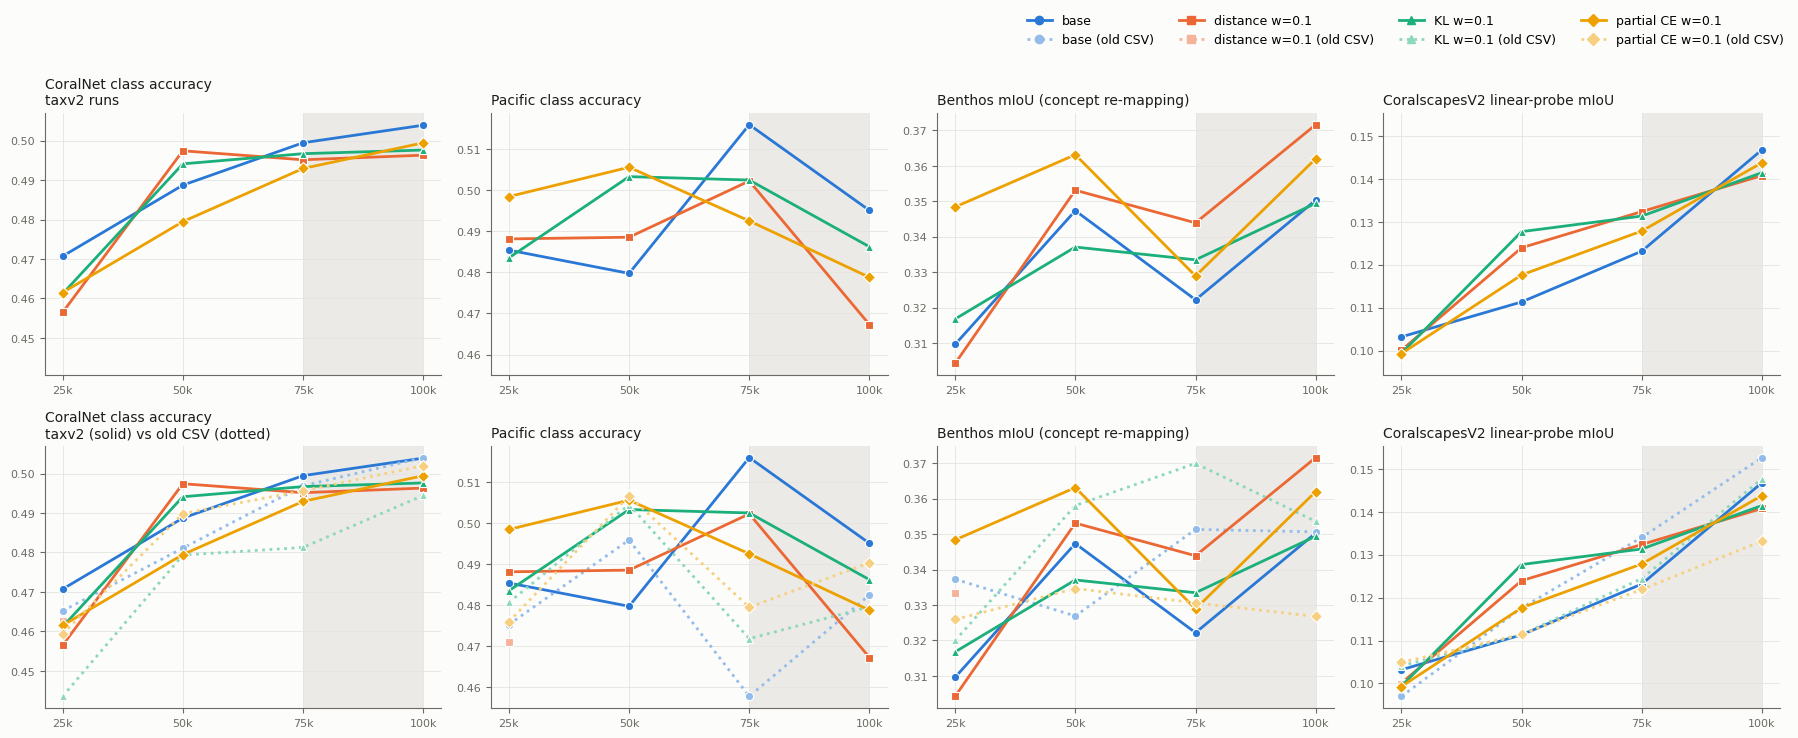

In [4]:
HEADLINE = [
    ("coralnet/class_accuracy", "CoralNet class accuracy"),
    ("pacific/class_accuracy", "Pacific class accuracy"),
    ("benthos/miou", "Benthos mIoU (concept re-mapping)"),
    ("coralscapes/miou", "CoralscapesV2 linear-probe mIoU"),
]
ALL_STEPS = sorted(df.index.get_level_values("step").unique())
fig, axes = plt.subplots(2, 4, figsize=(18, 7.4), sharey="col")
for row, runs, title in zip(axes, (NEW, NEW + OLD), ("taxv2 runs", "taxv2 (solid) vs old CSV (dotted)")):
    for ax, (col, name) in zip(row, HEADLINE):
        for run in sorted(runs, key=order):
            d = df.loc[run, col]
            plot_run(ax, run, d.index, d.values)
        ax.set_title(f"{name}\n{title}" if ax is row[0] else name)
        step_axis(ax, ALL_STEPS if runs is not NEW else NEW_STEPS)
run_legend(fig, sorted(NEW + OLD, key=order), ncol=4)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

**Reading** (all four checkpoints; 75k → 100k is the LR cooldown).
- **CoralNet class accuracy at 100k**: base 0.504, partial CE 0.499, KL 0.498, distance 0.496. Distance and KL led at 50k
  (0.497 / 0.494 vs 0.489), but base caught up by 75k and leads at both 75k and 100k. The spread at 100k is 0.8 pp.
- **Pacific** swings by 2–4 pp per checkpoint for every run (base 0.480 → 0.516 → 0.495 over 50k–100k; distance 0.502 →
  0.467 over the cooldown). At 100k base leads (0.495), then KL 0.486, partial CE 0.479, distance 0.467. With 4,419 points
  and swings this size, the Pacific order is not reliable.
- **Benthos at 100k**: distance 0.372 and partial CE 0.362 lead base (0.350) and KL (0.349). Partial CE is above base at all
  four steps; distance only at 50k, 75k and 100k.
- **CoralscapesV2 probe**: all four rise steadily and end within 0.6 pp of each other (0.141–0.147), with base highest. The
  losses' 50k lead over base did not hold.
- **New vs old (bottom row)**: at 100k the solid and dotted lines meet on CoralNet (base 0.504 both, KL +0.4, partial CE
  −0.3 pp). Partial CE gains most on Benthos (+3.5 pp) and CoralscapesV2 (+1.1 pp). The old distance run only has a 25k
  eval, so there is no old-vs-new comparison for it after 25k.

## 3. Old vs new, same loss, same step
`new − old` in percentage points at every step both have. Rows marked † are scored on each run's own tree, so they mix
the model change with the change in the tree.

In [5]:
OLD_NEW = [  # (column suffix, label, tree-dependent)
    ("class_accuracy", "class acc", False),
    ("class_miou", "class mIoU", False),
    *[(f"tax_{r}_acc_living", f"{r} acc (living) †", True) for r in RANKS[1:]],
    ("consistency/overall", "consistency (overall) †", True),
    ("severity/mean_normalized", "mistake severity ↓ †", True),
    ("ece/mean", "ECE ↓ †", True),
]
rows = []
for run in NEW:
    old = old_of(run)
    if old not in EVALUATED:
        continue
    for step in sorted(set(EVALUATED[run]) & set(EVALUATED[old])):
        r = {"run": style(run)[0], "step": f"{step // 1000}k"}
        for ev in EVALS:
            for suffix, label, _ in OLD_NEW:
                col = f"{ev}/{suffix}"
                r[(ev, label)] = 100 * (df.loc[(run, step), col] - df.loc[(old, step), col])
        for col, label in (("benthos/miou", "Benthos mIoU"), ("coralscapes/miou", "CoralscapesV2 mIoU")):
            r[("dense", label)] = 100 * (df.loc[(run, step), col] - df.loc[(old, step), col])
        rows.append(r)
old_new = pd.DataFrame(rows).set_index(["run", "step"])
old_new.columns = pd.MultiIndex.from_tuples(old_new.columns)
(old_new.T.style.format("{:+.1f}").background_gradient(cmap="RdBu", vmin=-6, vmax=6, axis=None)
 .set_caption("new − old (pp). ↓ rows: negative is better. † = tree-dependent."))

**Reading.**
- **Metrics that don't depend on the tree don't move.** At 100k, CoralNet class accuracy is within ±0.4 pp of the old run
  for base, KL and partial CE; Pacific within ±1.3 pp; CoralscapesV2 within ±1.1 pp. Across all steps both signs appear.
  The one sizeable shift is partial CE on Benthos (+3.5 pp at 100k, +2.2 to +2.8 pp at 25k–50k).
- **CoralNet rank accuracies (†) are higher for the new runs, but the gap shrinks with training.** At 50k base and KL were
  +4 to +5 pp at family and genus; at 100k the gains are +0.6 to +1.3 pp at family / genus and +1.3 to +2.8 pp at phylum /
  class. Partial CE at 100k is level (−0.4 to +1.4 pp). So most of the early gain was the new runs learning the ranks
  faster, not a lasting difference.
- **Consistency (†) is +4 to +5 pp for every run at every step on both evals**; section 4 shows where.
- **Mistake severity (†)** is about the same or slightly worse for the new runs (CoralNet at 100k: base +0.2, KL +0.9,
  partial CE +1.1 pp).
- † rows compare a model scored on the old tree with one scored on the new tree, so they mix both changes. Pacific rank
  accuracies are mixed in sign and come from only 4,419 points.

## 4. Where the consistency jump comes from
Lineage consistency per rank pair (share of points whose fine-head argmax is a child of the coarse-head argmax), new solid
vs old dotted.

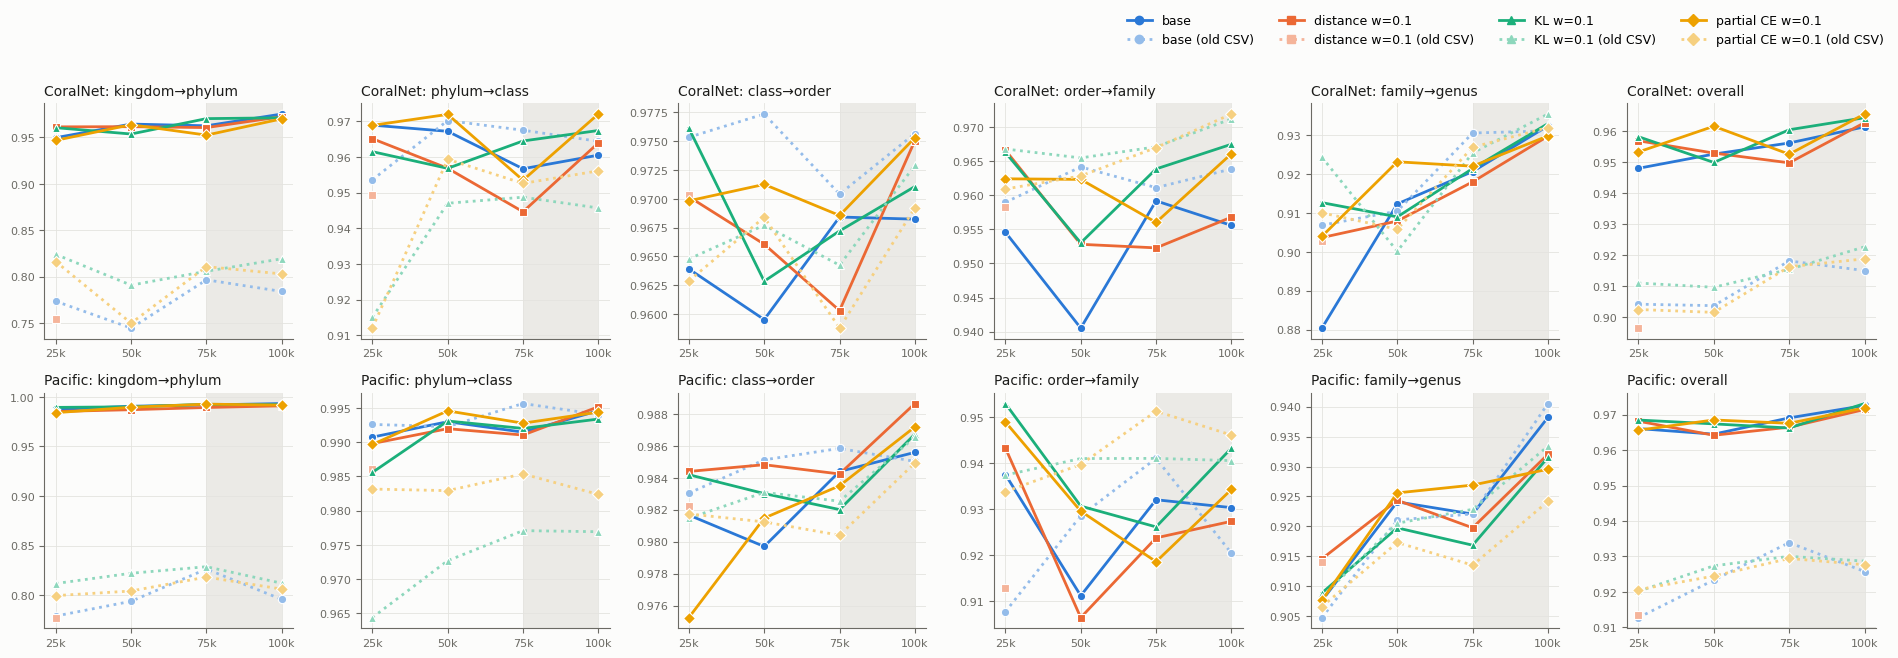

In [6]:
fig, axes = plt.subplots(2, len(PAIRS) + 1, figsize=(19, 6.6))
for row, ev in zip(axes, EVALS):
    for ax, pair in zip(row, PAIRS + ["overall"]):
        col = f"{ev}/consistency/{pair}"
        for run in sorted(NEW + OLD, key=order):
            d = df.loc[run, col]
            plot_run(ax, run, d.index, d.values)
        ax.set_title(f"{EVALS[ev].split(' ')[0]}: {pair.replace('->', '→')}")
        step_axis(ax, ALL_STEPS)
run_legend(fig, sorted(NEW + OLD, key=order), ncol=4)
fig.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

**Reading.**
- **Almost the whole jump is at kingdom→phylum**: CoralNet 0.75–0.82 (old) → 0.95–0.98 (new), Pacific 0.78–0.83 →
  0.98–0.99, for every loss including base and at every step. It persists through the cooldown (0.97 on CoralNet at 100k for
  all four new runs). Since the table is the only thing that differs, the change in the table causes it. I have not traced
  which part: seagrass gaining `phylum__tracheophyta` is the obvious candidate, but a ~20 pp swing is more than the seagrass
  points alone would explain, so it is worth checking with `scripts/dump_point_probs.py`.
- **Phylum→class** is also higher for the new KL / partial runs (CoralNet 0.946 / 0.956 old → 0.967 / 0.972 new at 100k);
  base was already there.
- **The other pairs show no systematic change.** Order→family is up to 0.02 lower for the new runs on CoralNet; family→genus is level (0.93 at 100k, old and new).
- **Overall** CoralNet consistency at 100k is 0.961–0.966 for the four new runs, compared with 0.915–0.923 for the old runs.

## 5. Scorecard: each loss vs the taxv2 baseline
`run − base [taxv2]` in percentage points, averaged over the steps both have; whiskers are the min / max over steps (a
whisker crossing 0 means the sign is not stable). Rows are oriented so **right = better**. All runs here are on the same
tree, so every row compares directly.

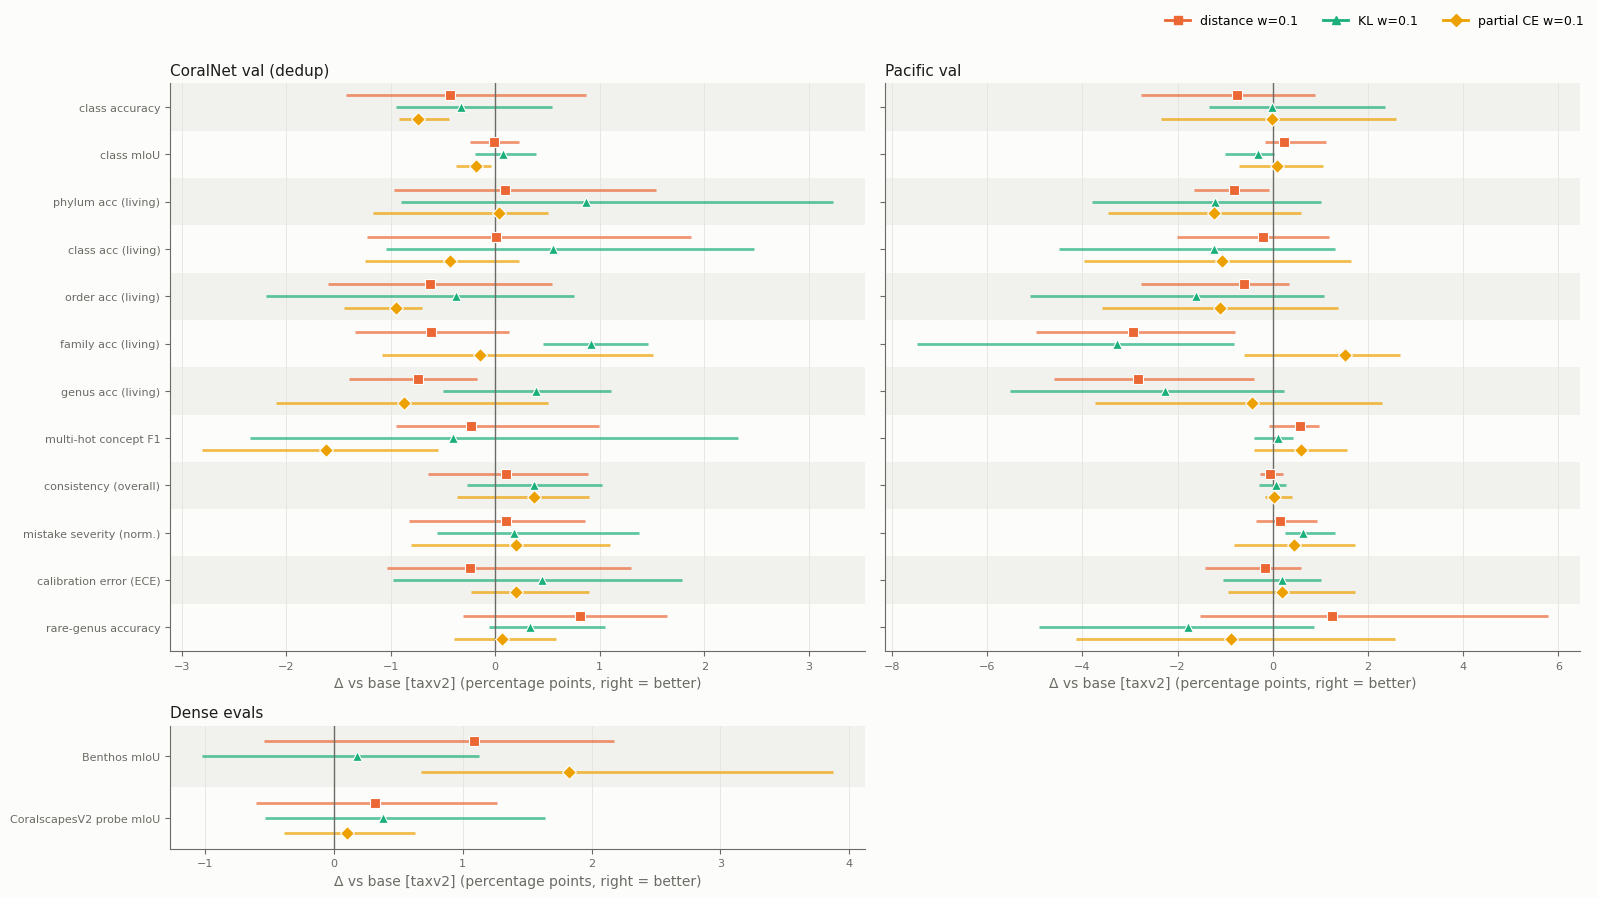

run,KL w=0.1,distance w=0.1,partial CE w=0.1
metric,,,
CoralNet class accuracy,-0.3,-0.4,-0.7
CoralNet class mIoU,+0.1,-0.0,-0.2
CoralNet phylum acc (living),+0.9,+0.1,+0.0
CoralNet class acc (living),+0.6,+0.0,-0.4
CoralNet order acc (living),-0.4,-0.6,-1.0
CoralNet family acc (living),+0.9,-0.6,-0.1
CoralNet genus acc (living),+0.4,-0.7,-0.9
CoralNet multi-hot concept F1,-0.4,-0.2,-1.6
CoralNet consistency (overall),+0.4,+0.1,+0.4


In [7]:
SCORECARD = [  # (column suffix, label, higher_is_better)
    ("class_accuracy", "class accuracy", True),
    ("class_miou", "class mIoU", True),
    *[(f"tax_{r}_acc_living", f"{r} acc (living)", True) for r in RANKS[1:]],
    ("binary_macro_f1", "multi-hot concept F1", True),
    ("consistency/overall", "consistency (overall)", True),
    ("severity/mean_normalized", "mistake severity (norm.)", False),
    ("ece/mean", "calibration error (ECE)", False),
    ("rare/genus/tail_macro_acc", "rare-genus accuracy", True),
]
OFFSETS = dict(zip(COMPARE, np.linspace(-0.25, 0.25, len(COMPARE))))


def scorecard(cols):
    rows = []
    for col, label, hib in cols:
        for run in COMPARE:
            d = (1 if hib else -1) * delta(run, col) * 100
            rows.append(dict(metric=label, run=run, mean=d.mean(), lo=d.min(), hi=d.max(), n=len(d)))
    return pd.DataFrame(rows)


def draw_scorecard(ax, sc, labels, title):
    y = {lab: i for i, lab in enumerate(labels)}
    for i in range(0, len(labels), 2):
        ax.axhspan(i - 0.5, i + 0.5, color=BAND, lw=0, zorder=0, alpha=0.6)
    for run, off in OFFSETS.items():
        _, color, marker, ls = style(run)
        s = sc[sc.run == run]
        yy = np.array([y[m] for m in s.metric]) + off
        ax.hlines(yy, s.lo, s.hi, color=color, lw=2, alpha=0.7)
        ax.scatter(s["mean"], yy, color=color, marker=marker, s=50, edgecolor="white", linewidth=0.8, zorder=3)
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_yticks(range(len(labels)), labels)
    ax.set_ylim(len(labels) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Δ vs base [taxv2] (percentage points, right = better)")
    ax.set_title(title, fontsize=11)


fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[len(SCORECARD), 2.6])
labels = [lab for _, lab, _ in SCORECARD]
for i, ev in enumerate(EVALS):
    ax = fig.add_subplot(gs[0, i])
    draw_scorecard(ax, scorecard([(f"{ev}/{c}", l, h) for c, l, h in SCORECARD]), labels, EVALS[ev])
    if i:
        ax.set_yticklabels([])
DENSE = [("benthos/miou", "Benthos mIoU", True), ("coralscapes/miou", "CoralscapesV2 probe mIoU", True)]
draw_scorecard(fig.add_subplot(gs[1, 0]), scorecard(DENSE), [l for _, l, _ in DENSE], "Dense evals")
run_legend(fig, COMPARE, ncol=3)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

sc = scorecard([(f"{ev}/{c}", f"{EVALS[ev].split(' ')[0]} {l}", h) for ev in EVALS for c, l, h in SCORECARD] + DENSE)
sc["run"] = sc.run.map(lambda r: style(r)[0])
(sc.pivot(index="metric", columns="run", values="mean").loc[sc.metric.unique()]
 .style.format("{:+.1f}").background_gradient(cmap="RdBu", vmin=-4, vmax=4, axis=None)
 .set_caption("mean Δ vs base [taxv2], pp, right = better (sign-flipped for ECE / severity)"))

**Reading** (averages over 25k–100k; whiskers span the four checkpoints). Only a few rows have all four steps on the same side
of 0:
- **No loss beats base on CoralNet class accuracy.** All three average below it (−0.3 to −0.7 pp); partial CE is behind at
  every step, distance and KL only led at 50k.
- **KL: CoralNet family accuracy is the one stable win** (+0.9 pp, +0.5 to +1.5 at every step), plus slightly better Pacific
  mistake severity (+0.6 pp). Against that, it is below base on Pacific family accuracy at every step (−3.3 pp on average,
  −0.8 pp at 100k).
- **Partial CE: Benthos is the one stable win** (+1.8 pp, +0.7 to +3.9 at every step). It is below base at every step on
  CoralNet class accuracy (−0.7), order accuracy (−1.0) and the multi-hot concept F1 (−1.6 pp).
- **Distance has no stable win.** It is below base at every step on CoralNet genus accuracy (−0.7 pp) and on Pacific
  phylum, family and genus accuracy (−0.8 / −2.9 / −2.8 pp).
- **Consistency, mistake severity and calibration** average within ±0.6 pp of base, with whiskers crossing 0 for all three
  losses. The ECE advantage seen at 50k did not last (section 7).
- **Sizes**: every average is under 2 pp on CoralNet and under 3.5 pp on Pacific, from a single seed.

## 6. Per-rank differences and each loss's own objective
`run − base [taxv2]` at each checkpoint, in raw units. Rows: per-rank accuracy on living points, lineage consistency per
rank pair, normalised mistake severity, and each loss's own objective (distance: expected tree distance; KL: inter-head
KL; partial CE: partial-label subtree mass).

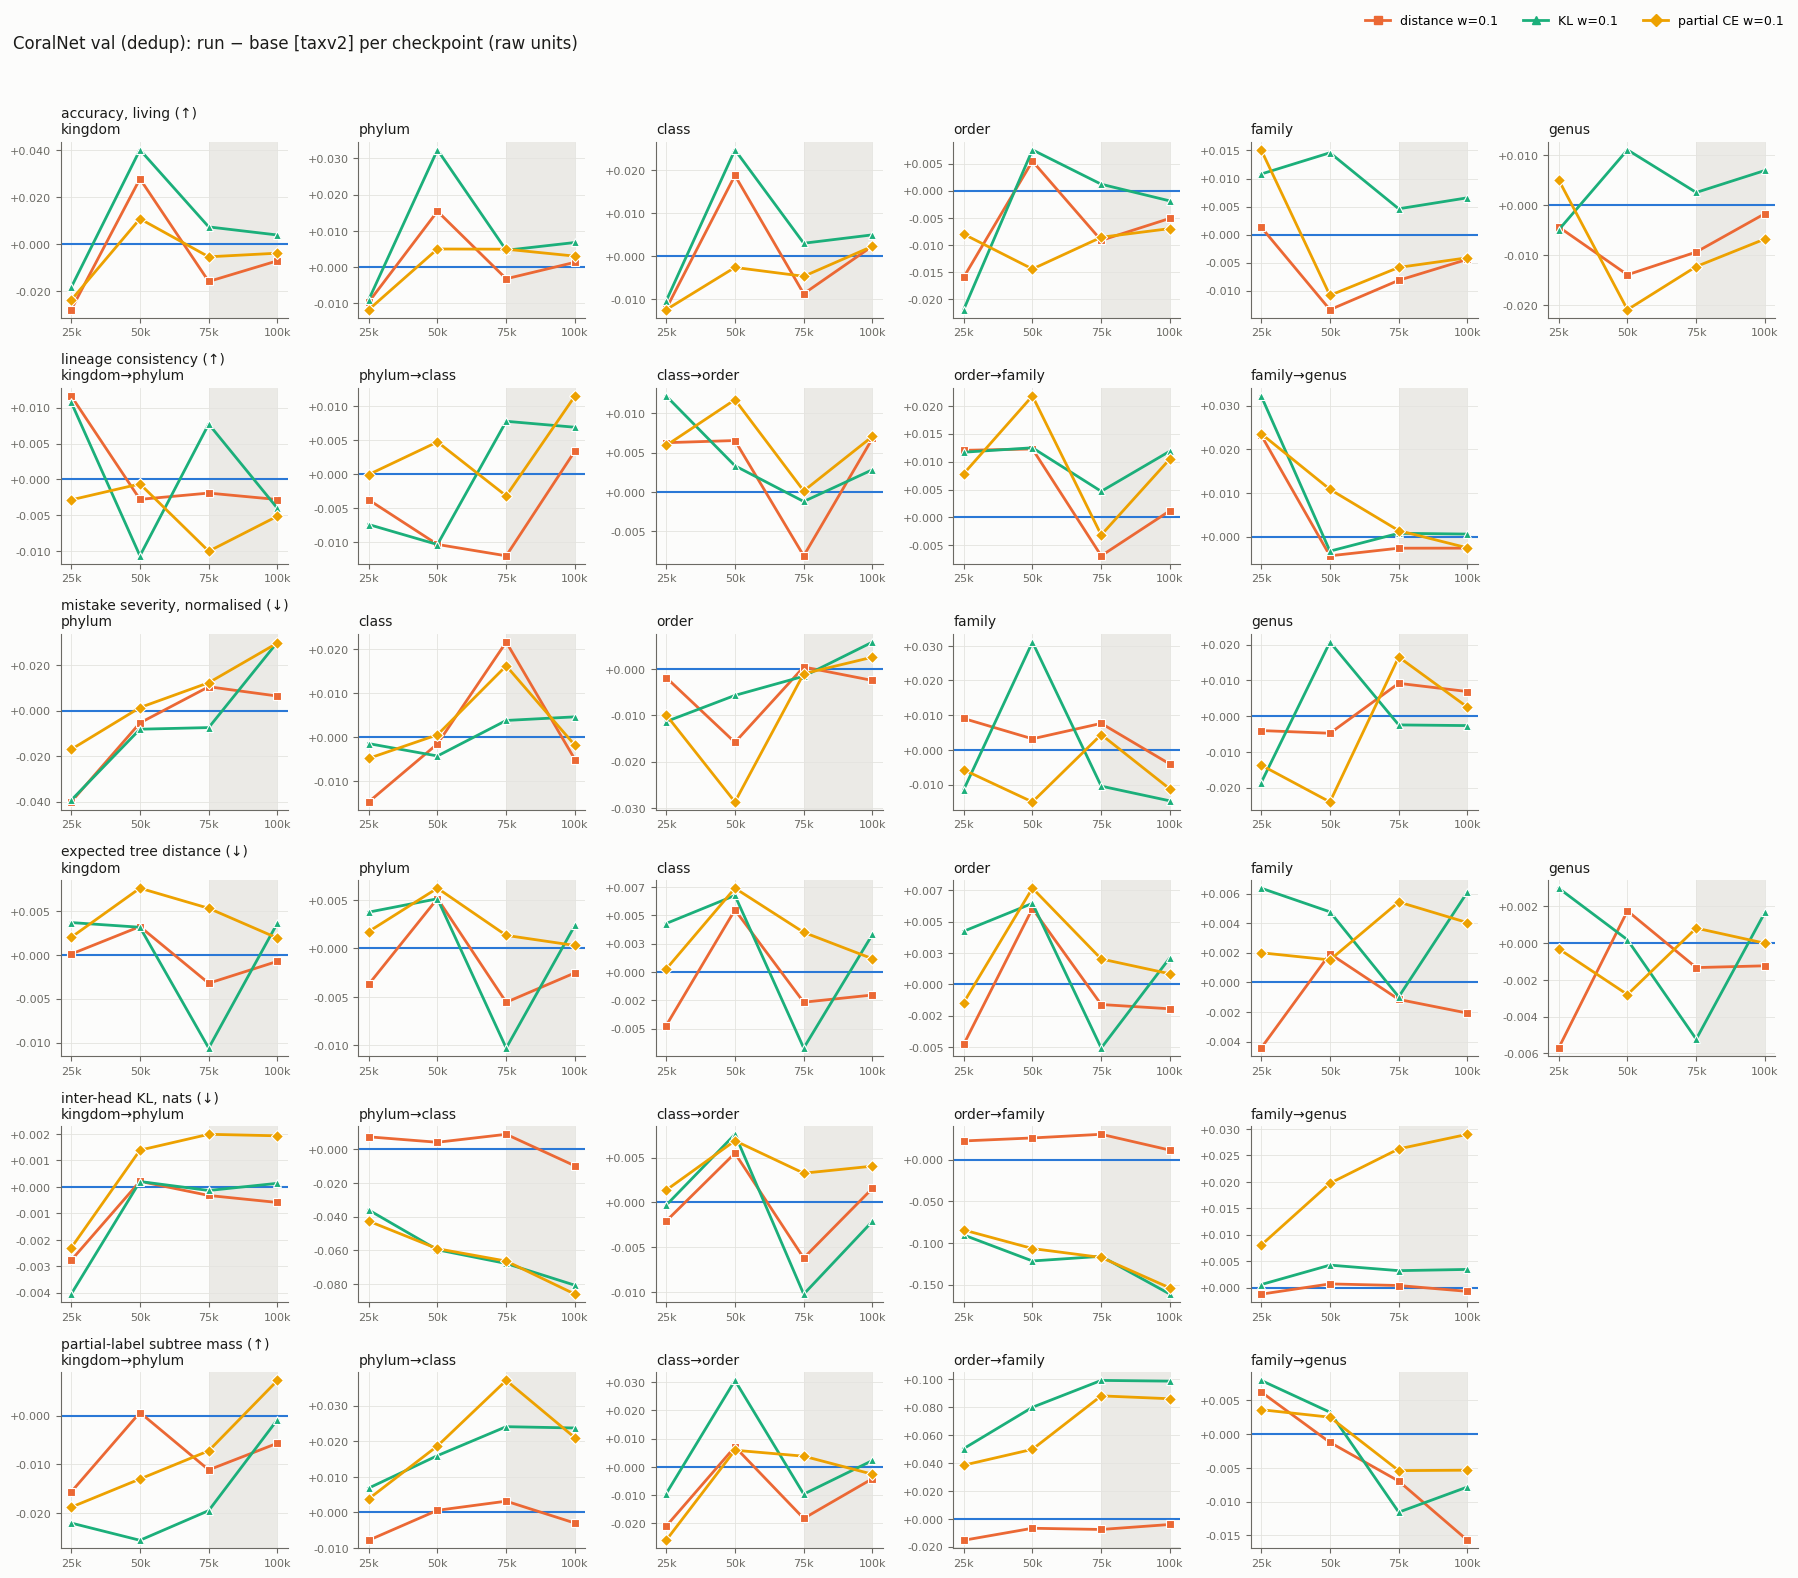

In [8]:
DELTA_ROWS = [  # (title, [(suffix, panel label)])
    ("accuracy, living (↑)", [(f"tax_{r}_acc_living", r) for r in RANKS]),
    ("lineage consistency (↑)", [(f"consistency/{p}", p.replace("->", "→")) for p in PAIRS]),
    ("mistake severity, normalised (↓)", [(f"severity/{r}/normalized", r) for r in RANKS[1:]]),
    ("expected tree distance (↓)", [(f"expected_distance/{r}", r) for r in RANKS]),
    ("inter-head KL, nats (↓)", [(f"kl/{p}", p.replace("->", "→")) for p in PAIRS]),
    ("partial-label subtree mass (↑)", [(f"partial/{p}/subtree_mass", p.replace("->", "→")) for p in PAIRS]),
]


def plot_deltas(ev):
    fig, axes = plt.subplots(len(DELTA_ROWS), 6, figsize=(18, 2.5 * len(DELTA_ROWS) + 0.8))
    for row_axes, (row_title, panels) in zip(axes, DELTA_ROWS):
        for i, ax in enumerate(row_axes):
            if i >= len(panels):
                ax.axis("off")
                continue
            suffix, label = panels[i]
            col = f"{ev}/{suffix}"
            ax.axhline(0, color=LOSSES["base"][1], lw=1.5)
            for run in COMPARE:
                d = delta(run, col)
                plot_run(ax, run, d.index, d.values)
            ax.set_title(label if i else f"{row_title}\n{label}")
            ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%+.3f"))
            step_axis(ax, NEW_STEPS)
    run_legend(fig, COMPARE, ncol=3)
    fig.suptitle(f"{EVALS[ev]}: run − base [taxv2] per checkpoint (raw units)", x=0.01, ha="left", fontsize=12, color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.965))
    plt.show()


plot_deltas("coralnet")

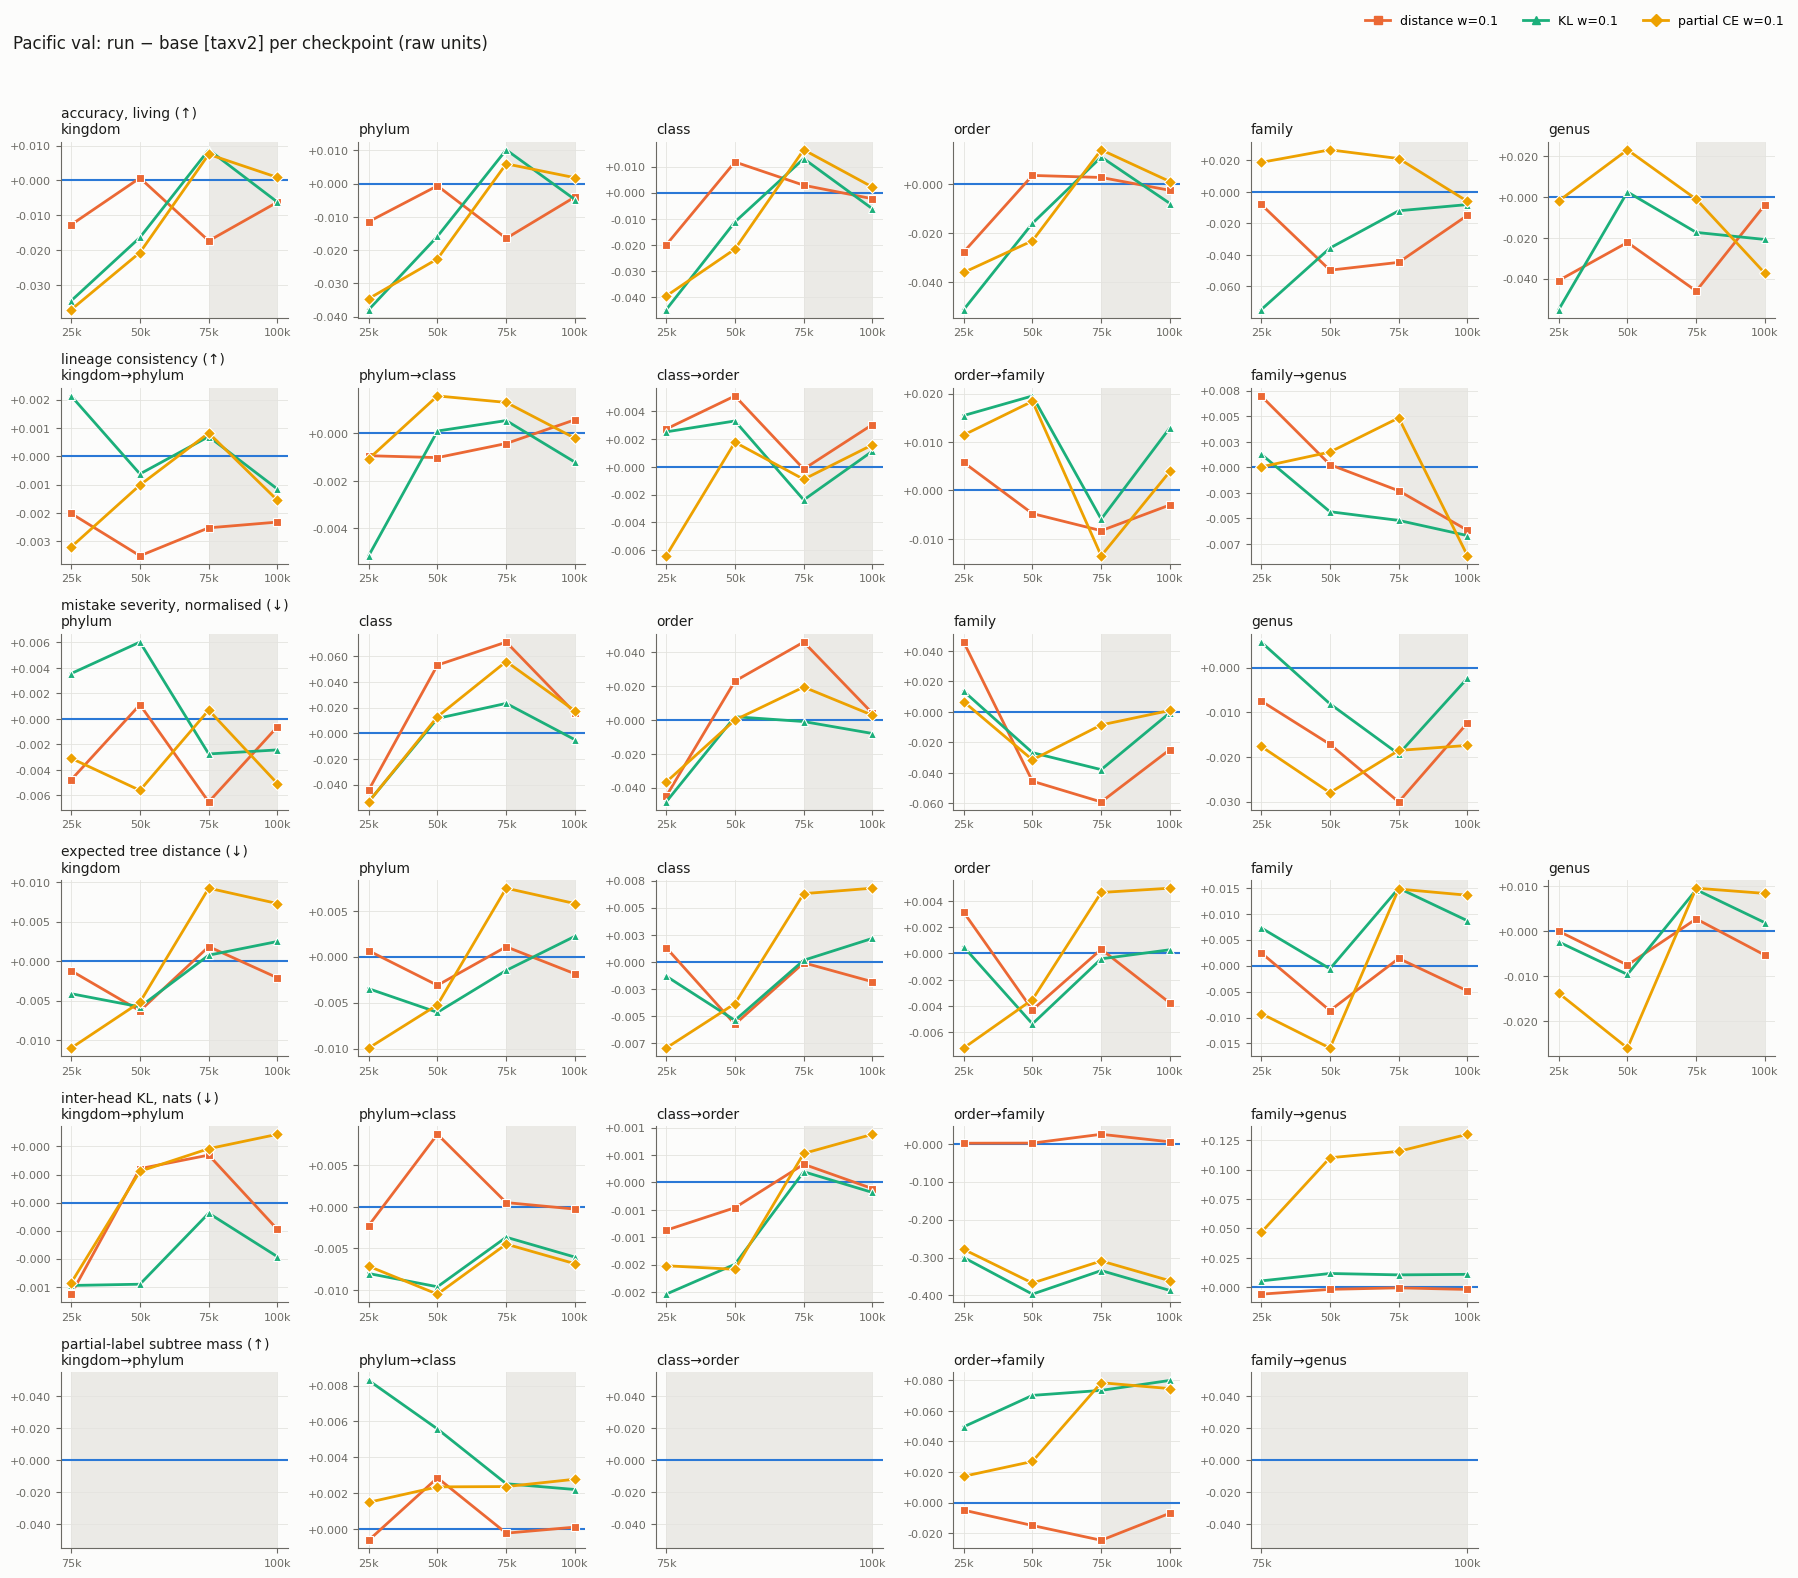

In [9]:
plot_deltas("pacific")

In [10]:
# Each loss's own objective, absolute values (CoralNet), new vs old, averaged over rank pairs / ranks
OBJ = {
    "expected tree distance ↓ (mean over ranks)": [f"coralnet/expected_distance/{r}" for r in RANKS],
    "inter-head KL ↓ (mean over pairs)": [f"coralnet/kl/{p}" for p in PAIRS],
    "partial-label subtree mass ↑ (mean over pairs)": [f"coralnet/partial/{p}/subtree_mass" for p in PAIRS],
}
obj = pd.DataFrame({
    (name, f"{s // 1000}k"): df[cols].mean(axis=1).xs(s, level="step")
    for name, cols in OBJ.items() for s in NEW_STEPS
}).loc[[r for r in sorted(NEW + OLD, key=order)]]
obj.index = [style(r)[0] for r in obj.index]
obj.style.format("{:.3f}").set_caption("CoralNet; old-CSV rows are on the old tree (†)")

**Reading.**
- **KL does what it is trained for**: the CoralNet inter-head KL stays at 0.031–0.038 nats across all four steps, while
  base's grows from 0.057 to 0.083; at 100k KL is less than half of base (0.035 vs 0.083), on Pacific less than a third
  (0.031 vs 0.107). Partial CE cuts it almost as much (0.042 / 0.060).
- **Partial-label subtree mass** is higher with KL (0.249 at 100k) and partial CE (0.247) than with base (0.226) on
  CoralNet, and on Pacific (0.256 / 0.254 vs 0.215). Partial CE was level with base at 25k and pulled ahead from 50k.
- **The distance loss does not lower expected tree distance**: 0.232 vs base 0.234 at 100k on CoralNet, 0.240 vs 0.243 on
  Pacific, and above base at 50k. As in the old runs, at w=0.1 its term is too weak to move its own objective.
- **The new table itself lowers the base model's inter-head KL** (0.083 vs 0.112 at 100k on CoralNet, †), consistent with
  turbinaria no longer being split across two families.

## 7. Calibration and rare taxa
`run − base [taxv2]` for the mean ECE over ranks, and macro accuracy over head (common) and tail (rare) taxa at family and
genus.

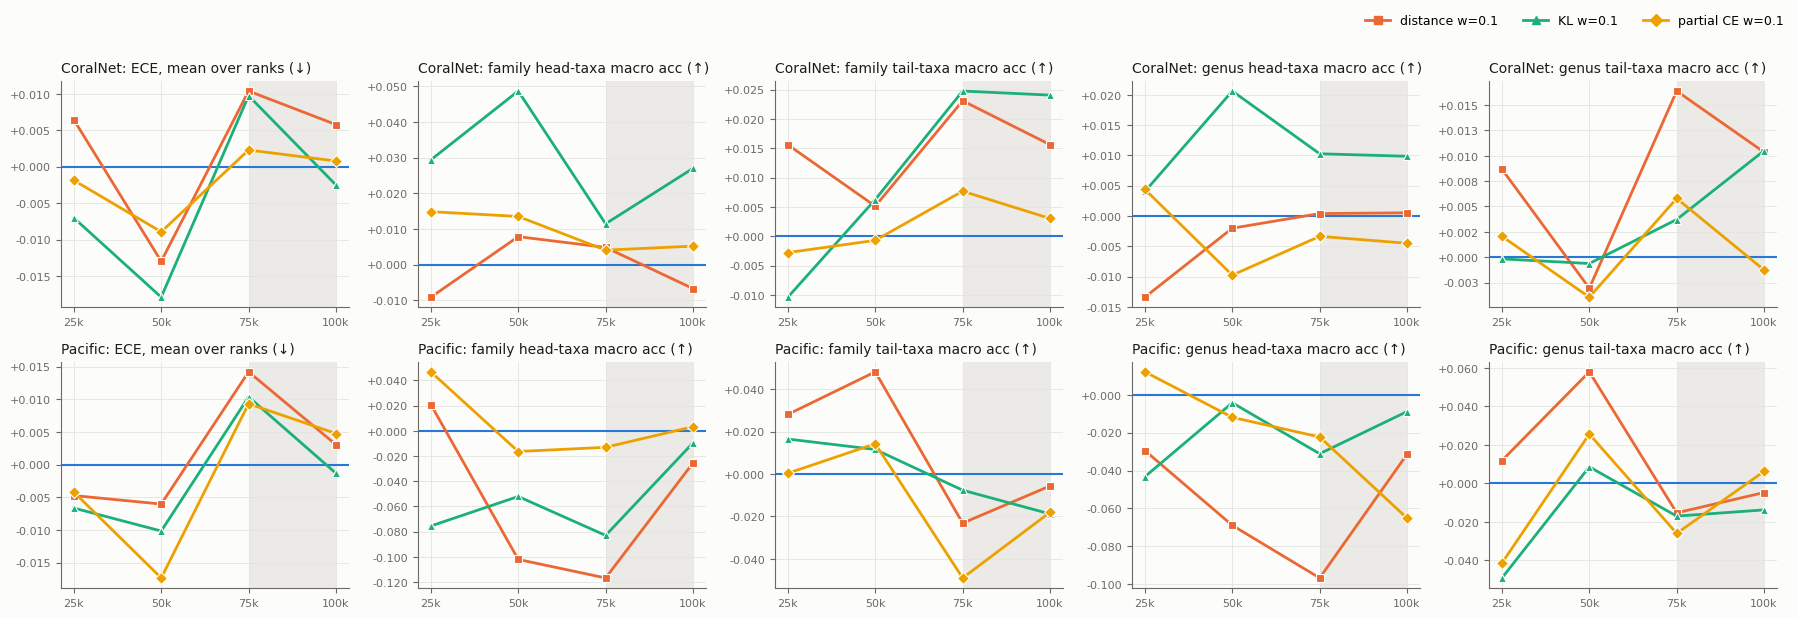

In [11]:
CALIB = [("ece/mean", "ECE, mean over ranks (↓)")] + [
    (f"rare/{r}/{s}_macro_acc", f"{r} {s}-taxa macro acc (↑)") for r in ("family", "genus") for s in ("head", "tail")]
fig, axes = plt.subplots(2, len(CALIB), figsize=(18, 6.2))
for row, ev in zip(axes, EVALS):
    for ax, (suffix, title) in zip(row, CALIB):
        ax.axhline(0, color=LOSSES["base"][1], lw=1.5)
        for run in COMPARE:
            d = delta(run, f"{ev}/{suffix}")
            plot_run(ax, run, d.index, d.values)
        ax.set_title(f"{EVALS[ev].split(' ')[0]}: {title}")
        ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%+.3f"))
        step_axis(ax, NEW_STEPS)
run_legend(fig, COMPARE, ncol=3)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

**Reading.**
- **ECE**: no loss is reliably better calibrated than base. At 50k all three were (CoralNet −0.9 to −1.8 pp), but base's ECE
  itself moves by about 1 pp between checkpoints (0.055 → 0.067 → 0.059 → 0.066), and at 100k the four runs are within
  0.8 pp (CoralNet 0.064–0.072, Pacific 0.021–0.027).
- **CoralNet head taxa**: KL is ahead of base at every step, at family (+1.2 to +4.8 pp; 0.325 vs 0.298 at 100k) and genus
  (+0.5 to +2.1 pp).
- **CoralNet tail taxa**: after 50k, KL and distance are ahead of base on tail family (+1.5 to +2.4 pp) and tail genus
  (+0.4 to +1.6 pp), but tail accuracies are only 2–6 %, so these are small absolute numbers.
- **Pacific**: distance's early lead on tail taxa is gone at 100k (family 0.371 vs 0.377, genus 0.311 vs 0.316), and it was
  far behind on head taxa at 75k (up to −12 pp). Pacific has few points per rare taxon, so these swing a lot.

## 8. Summary

1. **The fixed table makes the hierarchy consistent, not the classifier better.** Tree-independent metrics (class accuracy,
   CoralscapesV2, and Benthos except for partial CE) end the cooldown within ±1.3 pp of the old runs. CoralNet consistency
   rises from ~0.92 to ~0.96, almost all at kingdom→phylum. CoralNet rank accuracies (on the new tree) were +4 to +5 pp
   higher at 50k, but by 100k the gain is only +0.6 to +2.8 pp.
2. **After the full 100k schedule, base is best on the main metrics except Benthos.** It has the highest CoralNet and
   Pacific class accuracy and CoralscapesV2 mIoU at 100k; the losses' leads at 50k did not survive the cooldown.
3. **KL** does its job (inter-head KL less than half of base) and has the one stable CoralNet accuracy gain, at family
   (+0.9 pp on average), but it is worse than base on Pacific rank accuracy.
4. **Partial CE** is the only loss with a stable dense-eval gain (Benthos +1.8 pp on average, +1.2 pp at 100k), but it is
   slightly behind base on CoralNet class accuracy and concept F1 at every step.
5. **Distance at w=0.1** does not move its own objective and has no stable win; it is worst on Pacific.
6. **The earlier calibration finding does not hold**: the ECE gains at 50k disappear by 100k.
7. **Caveat**: one seed. Most differences between losses are 1–2 pp and change sign between checkpoints, and Pacific swings
   by 2–4 pp per checkpoint. A second seed, or larger weights, would be needed to separate the losses from noise.